In [1]:
%pip install pandas matplotlib seaborn scikit-learn python-pptx

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: pandas in c:\users\hp\appdata\local\programs\python\python310\lib\site-packages (2.3.3)
     ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
     ---------------------------------------- 0.1/8.2 MB 1.1 MB/s eta 0:00:08
      --------------------------------------- 0.1/8.2 MB 1.1 MB/s eta 0:00:08
      --------------------------------------- 0.1/8.2 MB 1.1 MB/s eta 0:00:08
      --------------------------------------- 0.2/8.2 MB 657.6 kB/s eta 0:00:13
      --------------------------------------- 0.2/8.2 MB 737.3 kB/s eta 0:00:11
     - -------------------------------------- 0.2/8.2 MB 722.1 kB/s eta 0:00:12
     - -------------------------------------- 0.2/8.2 MB 722.1 kB/s eta 0:00:12
     - -------------------------------------- 0.3/8.2 MB 655.4 kB/s eta 0:00:13
     - ---------------------------------


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



     ----------------------------- ---------- 5.3/7.2 MB 111.3 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 110.6 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 108.9 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 108.9 kB/s eta 0:00:18
     ----------------------------- ---------- 5.3/7.2 MB 108.9 kB/s eta 0:00:18
     ----------------------------- ----

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)

wine_data = wine.frame

wine_data["Wine Class"] = wine_data["target"].map({
    0: "Class 0",
    1: "Class 1",
    2: "Class 2"
})

wine_data = wine_data.drop("target", axis=1)

print(wine_data.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline Wine Class  
0       

In [7]:
print(wine_data.shape)

print(wine_data.columns)

print(wine_data.info())

print(wine_data.describe())

print(wine_data.isnull().sum())

(178, 14)
Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline', 'Wine Class'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins 

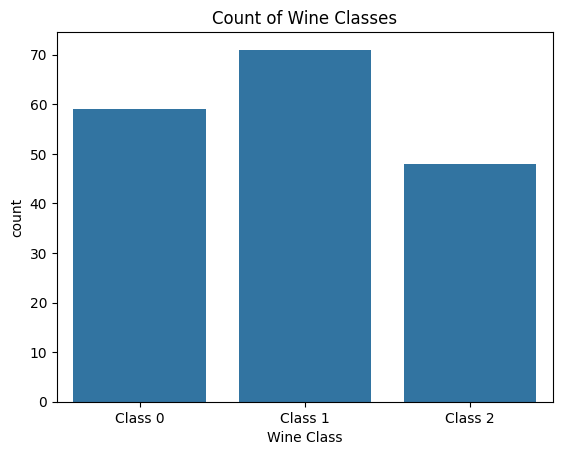

In [8]:
sns.countplot(data=wine_data, x="Wine Class")
plt.title("Count of Wine Classes")
plt.show()

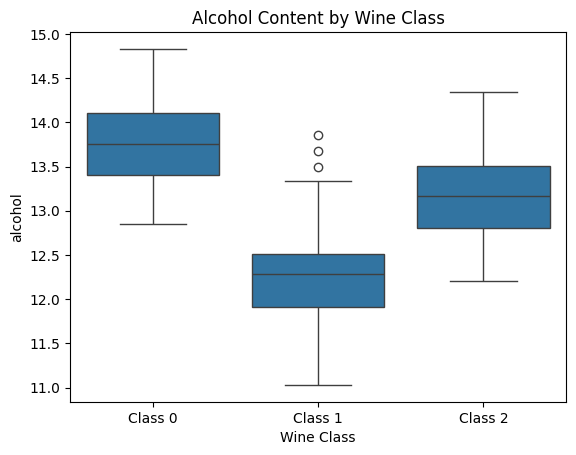

In [9]:
sns.boxplot(data=wine_data, x="Wine Class", y="alcohol")
plt.title("Alcohol Content by Wine Class")
plt.show()

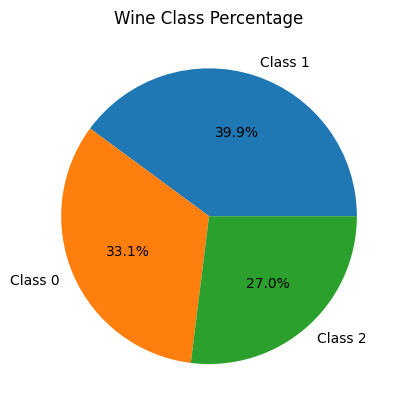

In [12]:
wine_data["Wine Class"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Wine Class Percentage")
plt.ylabel("")
plt.show()

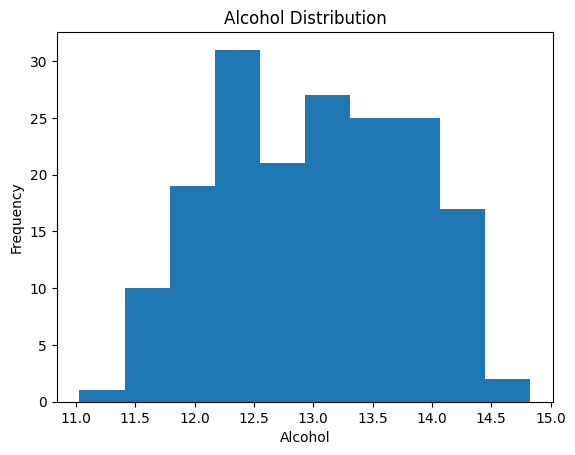

In [14]:
plt.hist(wine_data["alcohol"])

plt.title("Alcohol Distribution")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")
plt.show()

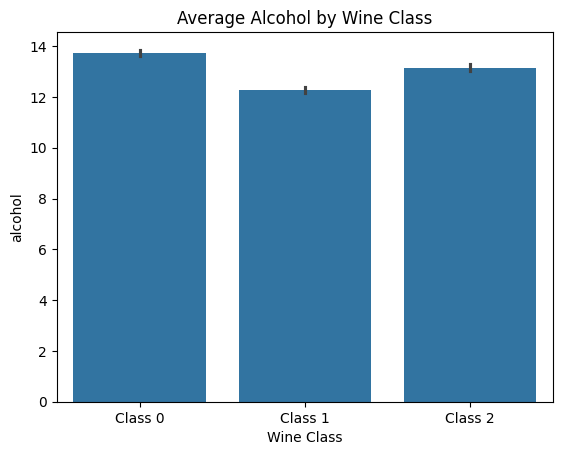

In [15]:
sns.barplot(data=wine_data, x="Wine Class", y="alcohol")

plt.title("Average Alcohol by Wine Class")
plt.show()

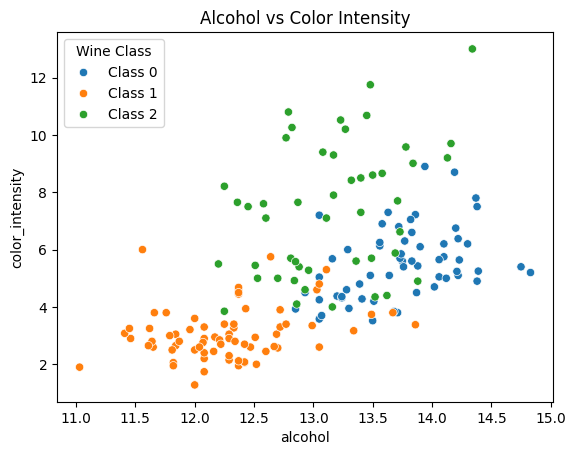

In [16]:
sns.scatterplot(
    data=wine_data,
    x="alcohol",
    y="color_intensity",
    hue="Wine Class"
)

plt.title("Alcohol vs Color Intensity")
plt.show()

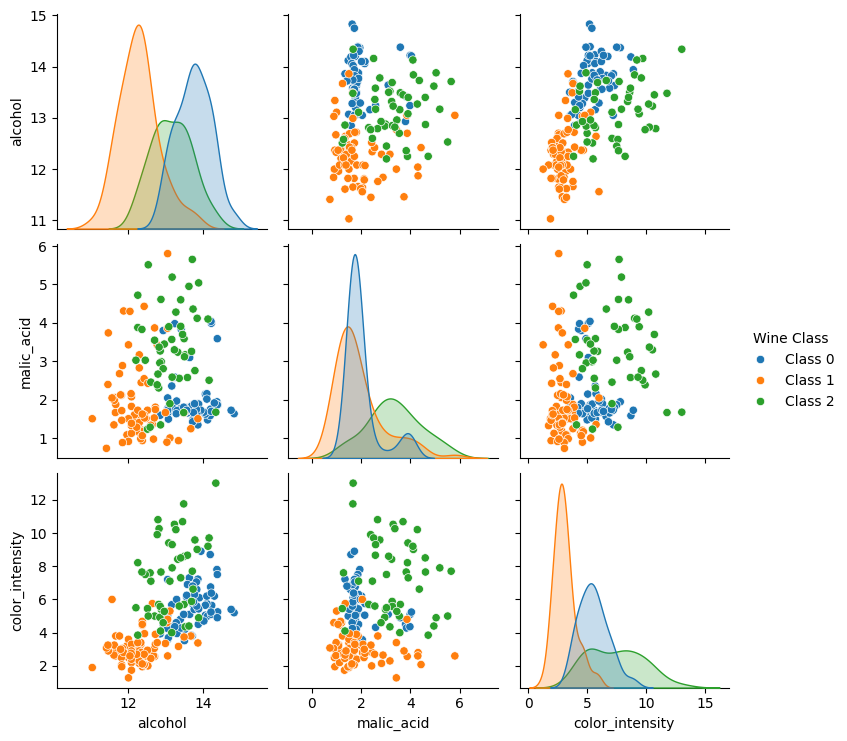

In [17]:
sns.pairplot(
    wine_data[["alcohol", "malic_acid", "color_intensity", "Wine Class"]],
    hue="Wine Class"
)

plt.show()

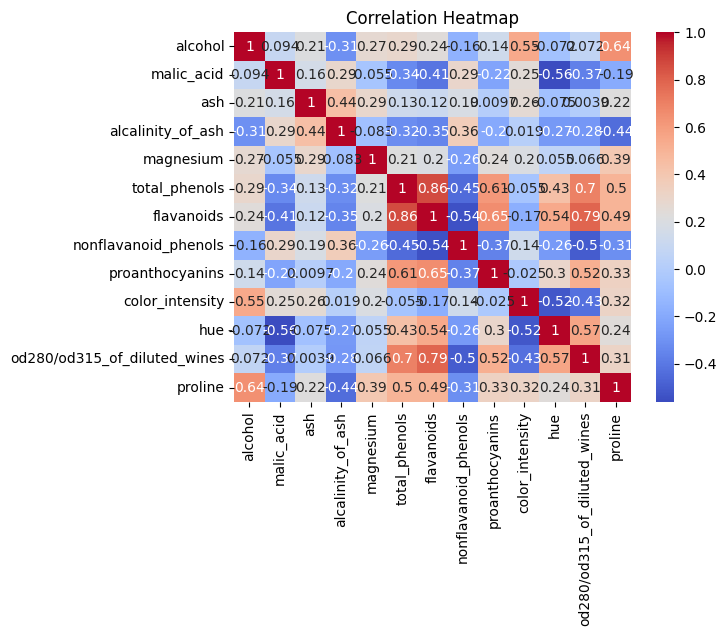

In [18]:
correlation = wine_data.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [19]:
print("Total rows and columns:", wine_data.shape)

print("\nWine Class Count:")
print(wine_data["Wine Class"].value_counts())

print("\nAverage Alcohol by Wine Class:")
print(wine_data.groupby("Wine Class")["alcohol"].mean())

print("\nAverage Color Intensity:")
print(wine_data.groupby("Wine Class")["color_intensity"].mean())

print("\nCorrelation between numerical columns:")
print(wine_data.select_dtypes(include="number").corr())

Total rows and columns: (178, 14)

Wine Class Count:
Wine Class
Class 1    71
Class 0    59
Class 2    48
Name: count, dtype: int64

Average Alcohol by Wine Class:
Wine Class
Class 0    13.744746
Class 1    12.278732
Class 2    13.153750
Name: alcohol, dtype: float64

Average Color Intensity:
Wine Class
Class 0    5.528305
Class 1    3.086620
Class 2    7.396250
Name: color_intensity, dtype: float64

Correlation between numerical columns:
                               alcohol  malic_acid       ash  \
alcohol                       1.000000    0.094397  0.211545   
malic_acid                    0.094397    1.000000  0.164045   
ash                           0.211545    0.164045  1.000000   
alcalinity_of_ash            -0.310235    0.288500  0.443367   
magnesium                     0.270798   -0.054575  0.286587   
total_phenols                 0.289101   -0.335167  0.128980   
flavanoids                    0.236815   -0.411007  0.115077   
nonflavanoid_phenols         -0.155929    0.2

In [20]:
from pptx import Presentation
from pptx.util import Inches, Pt
import os

os.makedirs("charts", exist_ok=True)

chart_names = [
    "Countplot",
    "Boxplot",
    "Piechart",
    "Histogram",
    "Barplot",
    "Scatterplot",
    "Pairplot",
    "Heatmap"
]

for name in chart_names:

    plt.figure(figsize=(8, 5))

    if name == "Countplot":
        sns.countplot(data=wine_data, x="Wine Class")

    elif name == "Boxplot":
        sns.boxplot(data=wine_data, x="Wine Class", y="alcohol")

    elif name == "Piechart":
        wine_data["Wine Class"].value_counts().plot(
            kind="pie", autopct="%1.1f%%"
        )

    elif name == "Histogram":
        plt.hist(wine_data["alcohol"], bins=10)

    elif name == "Barplot":
        sns.barplot(data=wine_data, x="Wine Class", y="alcohol")

    elif name == "Scatterplot":
        sns.scatterplot(
            data=wine_data, x="alcohol",
            y="color_intensity", hue="Wine Class"
        )

    elif name == "Pairplot":
        plt.close()

        g = sns.pairplot(
            wine_data[["alcohol", "malic_acid",
                "color_intensity", "Wine Class"]],
            hue="Wine Class"
        )

        g.savefig("charts/Pairplot.png")
        plt.close("all")
        continue

    elif name == "Heatmap":
        sns.heatmap(
            wine_data.select_dtypes(include="number").corr(),
            annot=True, cmap="coolwarm"
        )

    plt.title(name)
    plt.tight_layout()
    plt.savefig("charts/" + name + ".png")
    plt.close()

ppt = Presentation()

slide = ppt.slides.add_slide(ppt.slide_layouts[0])
slide.shapes.title.text = "Data Visualization Project"
slide.placeholders[1].text = "Wine Dataset Analysis using Python"

slide = ppt.slides.add_slide(ppt.slide_layouts[5])
slide.shapes.title.text = "Dataset Overview"

text = slide.shapes.add_textbox(
    Inches(1), Inches(1.5), Inches(10), Inches(4)
)

text.text_frame.text = (
    "Dataset: Wine Classification Dataset\n"
    "Total rows: " + str(wine_data.shape[0]) + "\n"
    "Total columns: " + str(wine_data.shape[1]) + "\n"
    "Missing values: " + str(wine_data.isnull().sum().sum())
)

for name in chart_names:

    slide = ppt.slides.add_slide(ppt.slide_layouts[5])
    slide.shapes.title.text = name

    slide.shapes.add_picture(
        "charts/" + name + ".png",
        Inches(1), Inches(1.3),
        width=Inches(10.5)
    )

slide = ppt.slides.add_slide(ppt.slide_layouts[5])
slide.shapes.title.text = "Conclusion"

text = slide.shapes.add_textbox(
    Inches(1), Inches(1.5), Inches(10), Inches(4)
)

text.text_frame.text = (
    "1. Countplot shows the number of wine samples in each class.\n"
    "2. Boxplot compares alcohol values between classes.\n"
    "3. Pie chart displays the percentage of each class.\n"
    "4. Histogram shows the distribution of alcohol values.\n"
    "5. Barplot compares average alcohol values.\n"
    "6. Scatterplot shows the relationship between two features.\n"
    "7. Pairplot compares multiple numerical features.\n"
    "8. Heatmap shows correlations between numerical features."
)

ppt.save("Data_Visualization_Project.pptx")

print("PowerPoint created successfully!")

PowerPoint created successfully!
